# Dimensionality Reduction & Clustering

Builds one gene-trajectory AnnData (`traj`: rows are gene × context trajectories, columns aligned time points) from the final 8-knot tradeSeq fits of the three contexts, characterizes each trajectory, and clusters the significant ones into dynamic modes, separately for induced and repressed genes.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import chronopack as cp

In [2]:
# Folder holding one sub-folder per experiment; see analyses/README.md.
DATA_DIR = Path(os.environ.get("CHRONOPACK_DATA_DIR", "../data"))
root_k562a = (DATA_DIR / "k562-tnfa.hg38.rep").resolve()
root_lps = (DATA_DIR / "thp1-k562-lps.hg38.rep").resolve()

OUTPUT_DIR = (DATA_DIR / "gene_clustering").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Build and characterize gene trajectories

Fitted curves are aligned onto a common time axis (time span, onset offset and THP1 time scaling per context); association statistics come from `rowData(sce)`. Descriptors (onset, peak, log2 fold change, curvature, ...) are added to `traj.obs`.

In [3]:
sce_dict = {
    "K562a": root_k562a / "intmd" / "sc-K562-1e4_to_tradeSeq.fixed" / "sce.1trajectory.nknots8.rds",
    "K562b": root_lps / "intmd" / "sc-K562_to_tradeSeq.fixed" / "sce.1trajectory.nknots8.rds",
    "THP1": root_lps / "intmd" / "sc-THP1_to_tradeSeq.fixed" / "sce.1trajectory.nknots8.rds",
}
traj = cp.tl.align_gene_trajectories(
    sce_dict,
    time_map={"K562a": 110, "K562b": 165, "THP1": 165},
    offset_map={"K562a": 0, "K562b": -68, "THP1": -10},
    scale_map={"THP1": 0.65},
)
traj = cp.tl.compute_gene_trajectory_descriptors(traj, inplace=False)
traj.write_h5ad(OUTPUT_DIR / "gene_trajectory_characterization.h5ad")
traj

[K562a] TMAX=110, scale=1, offset=0 => aligned range 0.00..110.00, resampled to 110 minute points
[K562b] TMAX=165, scale=1, offset=-68 => aligned range 0.00..97.00, resampled to 97 minute points
[THP1] TMAX=165, scale=0.65, offset=-10 => aligned range 0.40..97.25, resampled to 97 minute points
Shortest aligned end time across keys after rescaling: 97 min
Final shared aligned minute range: 1 .. 97  (n = 97 )


R callback write-console: Loading required package: SingleCellExperiment
  
R callback write-console: Loading required package: SummarizedExperiment
  
R callback write-console: Loading required package: MatrixGenerics
  
R callback write-console: Loading required package: matrixStats
  
R callback write-console: 
Attaching package: 'MatrixGenerics'

  
R callback write-console: The following objects are masked from 'package:matrixStats':

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCu

AnnData object with n_obs × n_vars = 5091 × 97
    obs: 'gene', 'cell_type', 'waldStat_1', 'meanLogFC', 'pvalue_1', 'qval_1', 't_onset', 't_peak', 'baseline_exp', 'peak_exp', 'peak_dlogexp', 'peak_dexp', 'peak_log2fc', 'auc_norm', 'owp', 'owp_ddt', 'mean_curv', 'max_curv', 'mean_turn', 'max_turn'
    var: 'time'
    uns: 'chronopack'

## Cluster dynamic modes

Significant trajectories (`pvalue_1` < 0.05) are split into induced (peak log2 fold change > 0) and repressed (< 0). Each set is clustered for every candidate k, with features scaled against all significant trajectories. Broad modes use k = 3; fine modes use the k with the highest elbow score.

In [4]:
PVALUE_THRESHOLD = 0.05
ALPHA = 0.1
K_GRID = range(2, 101)
BROAD_K = 3

sig = traj[traj.obs["pvalue_1"] < PVALUE_THRESHOLD].copy()
induced = sig[sig.obs["peak_log2fc"] > 0].copy()
repressed = sig[sig.obs["peak_log2fc"] < 0].copy()
{"significant": sig.n_obs, "induced": induced.n_obs, "repressed": repressed.n_obs}

{'significant': 5091, 'induced': 2424, 'repressed': 2667}

### Induced

In [5]:
induced_clust = cp.tl.cluster_gene_trajectories(induced, k=K_GRID, reference=sig, alpha=ALPHA)
induced_clust.metrics.to_csv(OUTPUT_DIR / "cluster_metrics.induced.csv", index=False)

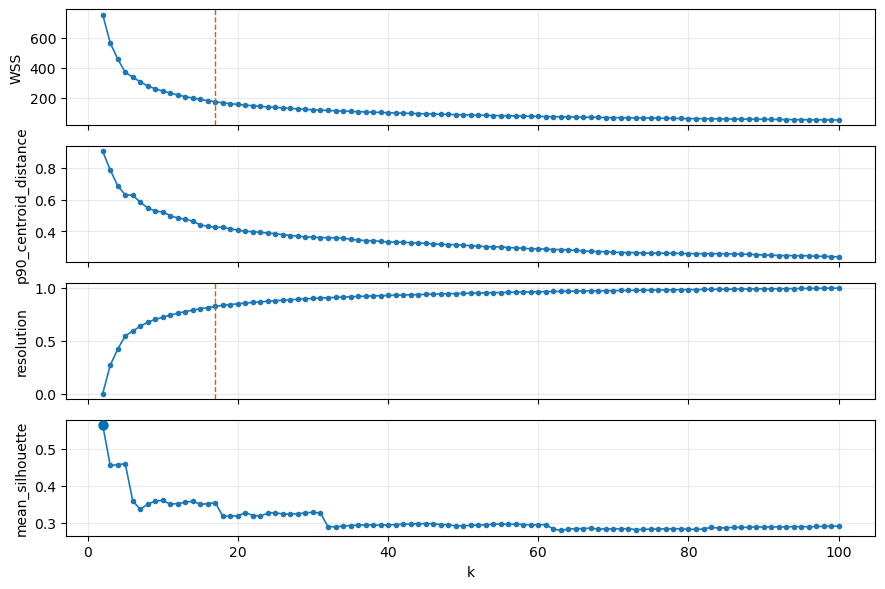

In [6]:
cp.pl.clustering_metrics(induced_clust, output=OUTPUT_DIR / "cluster_metric_selection.induced.png")
plt.show()

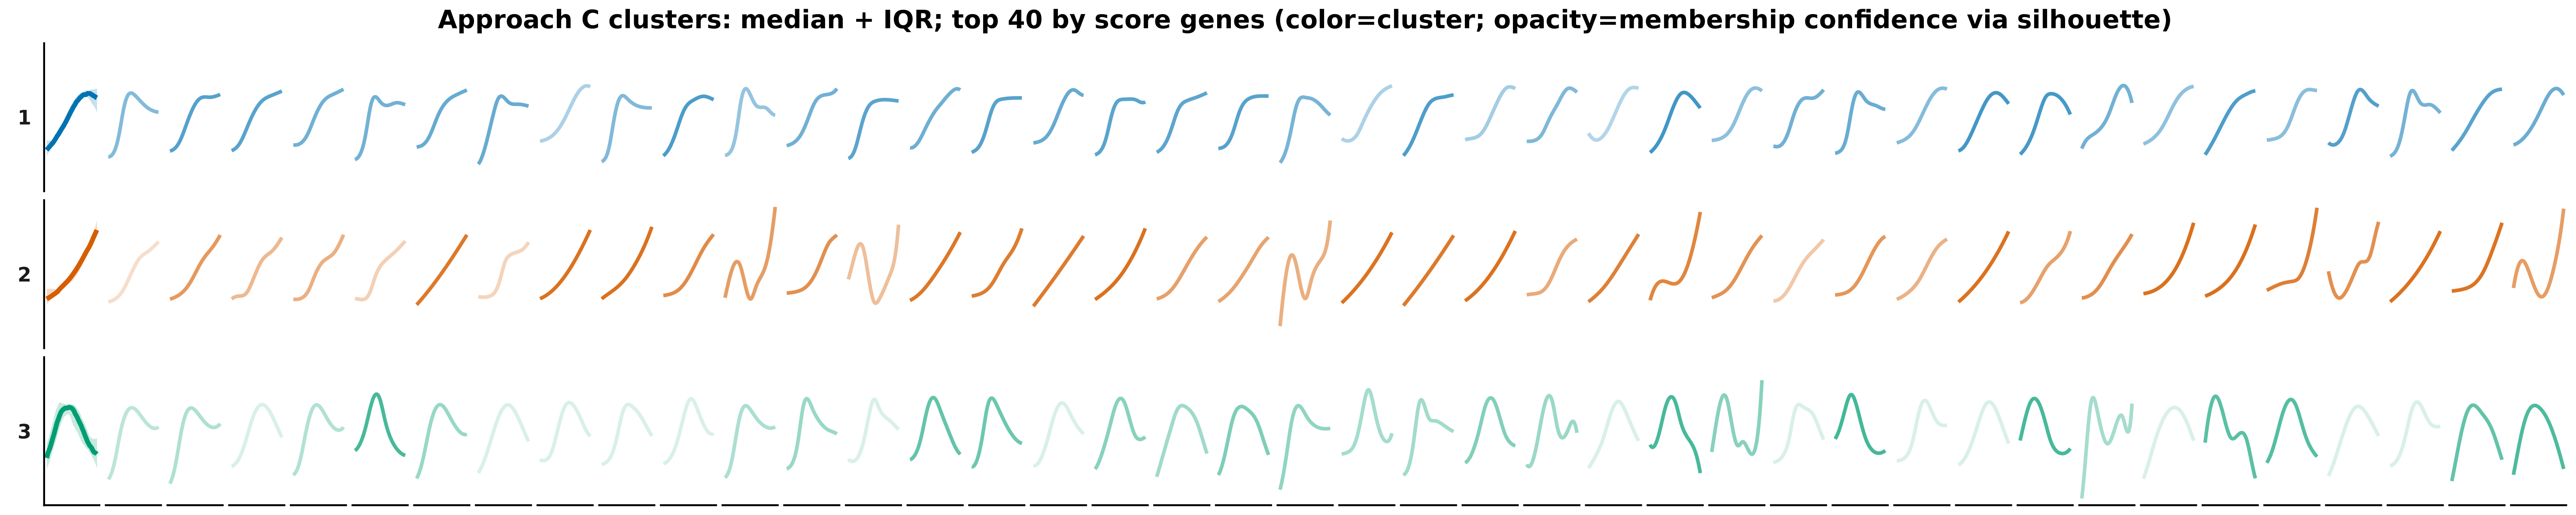

In [7]:
# Prospective broad modes (k = BROAD_K): per cluster the median + IQR, then the top trajectories
# by Wald statistic (opacity = silhouette width).
cp.pl.cluster_medoids_and_top_genes(
    induced,
    induced_clust.assignments[BROAD_K],
    features=induced_clust.features,
    seed=10,
    top_n=40,
    show_sil_text=False,
    show_median_iqr=True,
    output=OUTPUT_DIR / "broad_cluster_medoids.induced.png",
    width=20,
    height=4,
)


In [8]:
# Fine modes: the k with the highest elbow score; broad modes: BROAD_K.
induced_fine_k = int(induced_clust.metrics.loc[induced_clust.metrics["elbow_score"].idxmax(), "k"])
induced_fine_k

17

In [9]:
traj.obs["cluster_broad_induced"] = induced_clust.assignments[BROAD_K].astype(str).map({"1": "impulse-up_1", "2": "trend-up", "3": "impulse-up_2"})
traj.obs["cluster_dist_broad_induced"] = induced_clust.centroid_distances[BROAD_K]
traj.obs["cluster_fine_induced"] = induced_clust.assignments[induced_fine_k].astype(str)
traj.obs["cluster_dist_fine_induced"] = induced_clust.centroid_distances[induced_fine_k]
traj.obs.loc[induced.obs_names, "cluster_broad_induced"].value_counts()

cluster_broad_induced
trend-up        1478
impulse-up_2     474
impulse-up_1     472
Name: count, dtype: int64

### Repressed

In [10]:
repressed_clust = cp.tl.cluster_gene_trajectories(repressed, k=K_GRID, reference=sig, alpha=ALPHA)
repressed_clust.metrics.to_csv(OUTPUT_DIR / "cluster_metrics.repressed.csv", index=False)

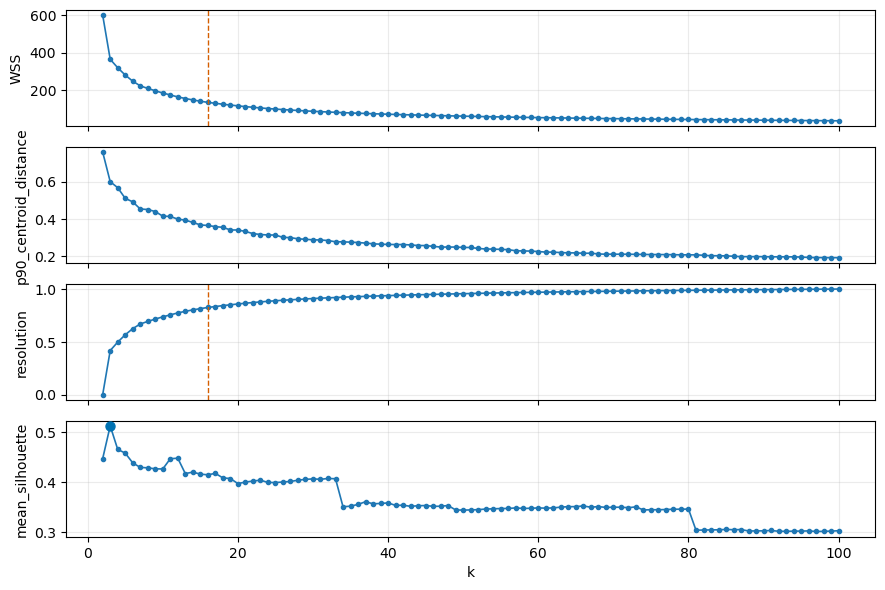

In [11]:
cp.pl.clustering_metrics(repressed_clust, output=OUTPUT_DIR / "cluster_metric_selection.repressed.png")
plt.show()

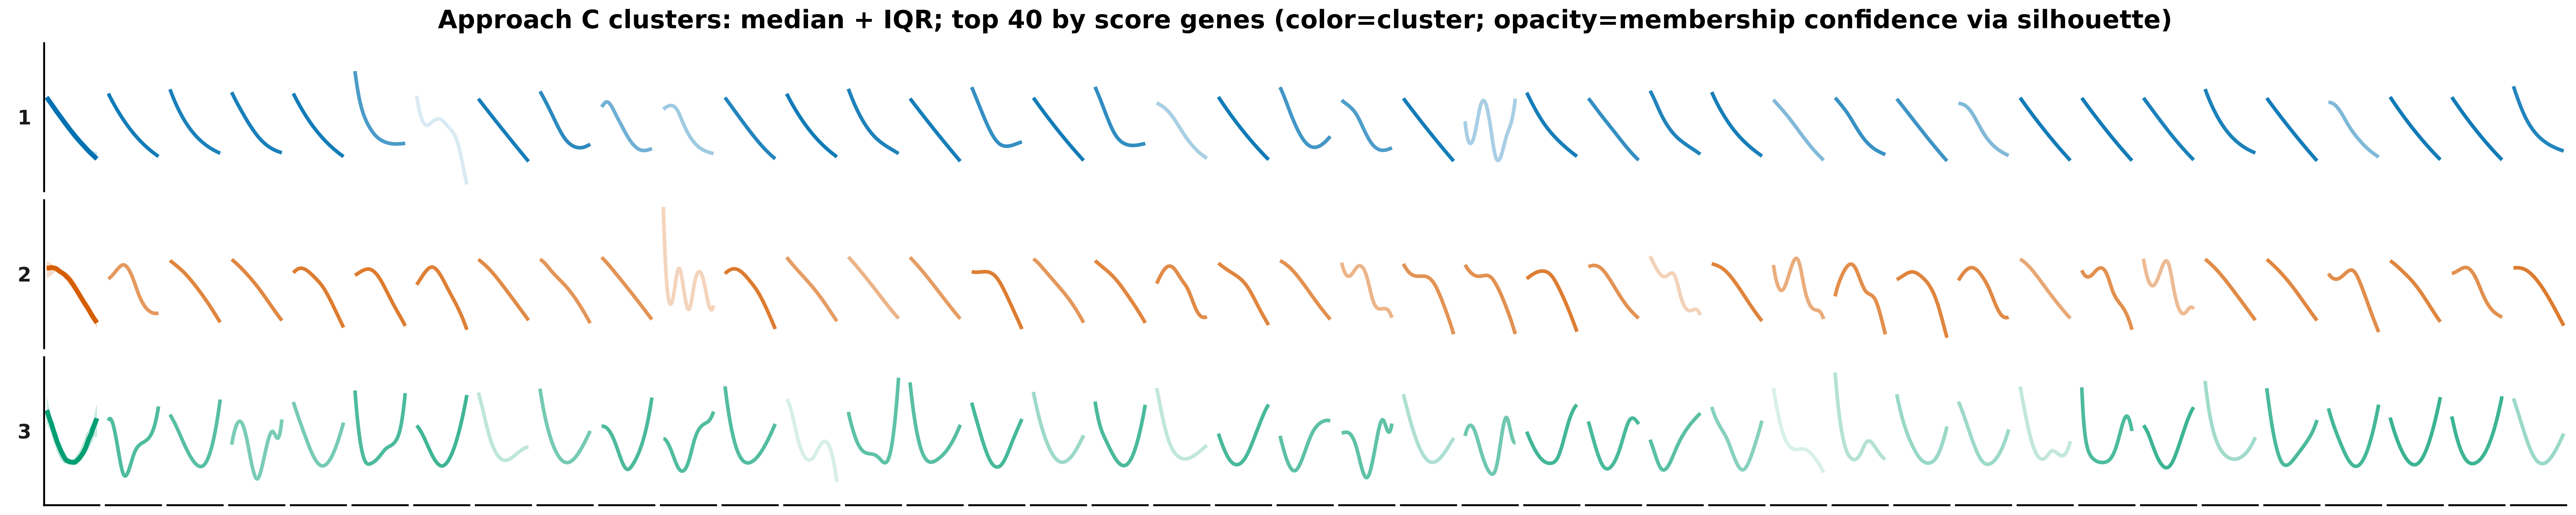

In [12]:
# Prospective broad modes (k = BROAD_K): per cluster the median + IQR, then the top trajectories
# by Wald statistic (opacity = silhouette width).
cp.pl.cluster_medoids_and_top_genes(
    repressed,
    repressed_clust.assignments[BROAD_K],
    features=repressed_clust.features,
    seed=10,
    top_n=40,
    show_sil_text=False,
    show_median_iqr=True,
    output=OUTPUT_DIR / "broad_cluster_medoids.repressed.png",
    width=20,
    height=4,
)


In [13]:
# Fine modes: the k with the highest elbow score; broad modes: BROAD_K.
repressed_fine_k = int(repressed_clust.metrics.loc[repressed_clust.metrics["elbow_score"].idxmax(), "k"])
repressed_fine_k

16

In [14]:
traj.obs["cluster_broad_repressed"] = repressed_clust.assignments[BROAD_K].astype(str).map({"1": "trend-down_1", "2": "trend-down_2", "3": "transient-down"})
traj.obs["cluster_dist_broad_repressed"] = repressed_clust.centroid_distances[BROAD_K]
traj.obs["cluster_fine_repressed"] = repressed_clust.assignments[repressed_fine_k].astype(str)
traj.obs["cluster_dist_fine_repressed"] = repressed_clust.centroid_distances[repressed_fine_k]
traj.obs.loc[repressed.obs_names, "cluster_broad_repressed"].value_counts()

cluster_broad_repressed
trend-down_1      1521
trend-down_2       897
transient-down     249
Name: count, dtype: int64

## Combine modes

Trajectories outside a set keep the label `-1`. `broad_cluster` takes the induced broad mode, or the repressed one for repressed trajectories. The PCA of trajectory shapes used for clustering is stored in `traj.obsm["X_pca"]` (first 4 components), the clustering features (scaled shape and derivative) in `traj.obsm["X_cluster_features"]`.

In [15]:
for col in ["cluster_broad_induced", "cluster_fine_induced", "cluster_broad_repressed", "cluster_fine_repressed"]:
    traj.obs[col] = traj.obs[col].fillna("-1").astype(str)

traj.obs["broad_cluster"] = traj.obs["cluster_broad_induced"].where(
    traj.obs["cluster_broad_induced"] != "-1", traj.obs["cluster_broad_repressed"]
)
traj.obs["cluster_dist_broad"] = traj.obs["cluster_dist_broad_induced"].combine_first(traj.obs["cluster_dist_broad_repressed"])
traj.obs["cluster_dist_fine"] = traj.obs["cluster_dist_fine_induced"].combine_first(traj.obs["cluster_dist_fine_repressed"])

# Both clusterings share one PCA of trajectory shapes, fitted on all significant trajectories (the reference).
traj.obsm["X_pca"] = induced_clust.pca.iloc[:, :4].reindex(traj.obs_names).to_numpy()
# The joint shape + derivative features distances were computed on (medoid plots in 02).
features = pd.concat([induced_clust.features, repressed_clust.features])
traj.obsm["X_cluster_features"] = features.reindex(traj.obs_names).to_numpy()

traj.write_h5ad(OUTPUT_DIR / "gene_trajectory_clusters.h5ad")
traj.obs["broad_cluster"].value_counts()

broad_cluster
trend-down_1      1521
trend-up          1478
trend-down_2       897
impulse-up_2       474
impulse-up_1       472
transient-down     249
Name: count, dtype: int64